In [27]:
import pandas as pd
import ast
import numpy as np

In [2]:
data  = pd.read_csv('../data/RAW_recipes.csv')
data.set_index('id', inplace=True)
data["tags"] = data["tags"].apply(ast.literal_eval)
data

,name,minutes,contributor_id,submitted,tags,nutrition,n_steps,steps,description,ingredients,n_ingredients
id,,,,,,,,,,,
137739,arriba baked winter squash mexican style,55,47892,2005-09-16,"[60-minutes-or-less, time-to-make, course, mai...","[51.5, 0.0, 13.0, 0.0, 2.0, 0.0, 4.0]",11,"['make a choice and proceed with recipe', 'dep...",autumn is my favorite time of year to cook! th...,"['winter squash', 'mexican seasoning', 'mixed ...",7
31490,a bit different breakfast pizza,30,26278,2002-06-17,"[30-minutes-or-less, time-to-make, course, mai...","[173.4, 18.0, 0.0, 17.0, 22.0, 35.0, 1.0]",9,"['preheat oven to 425 degrees f', 'press dough...",this recipe calls for the crust to be prebaked...,"['prepared pizza crust', 'sausage patty', 'egg...",6
112140,all in the kitchen chili,130,196586,2005-02-25,"[time-to-make, course, preparation, main-dish,...","[269.8, 22.0, 32.0, 48.0, 39.0, 27.0, 5.0]",6,"['brown ground beef in large pot', 'add choppe...",this modified version of 'mom's' chili was a h...,"['ground beef', 'yellow onions', 'diced tomato...",13
59389,alouette potatoes,45,68585,2003-04-14,"[60-minutes-or-less, time-to-make, course, mai...","[368.1, 17.0, 10.0, 2.0, 14.0, 8.0, 20.0]",11,['place potatoes in a large pot of lightly sal...,"this is a super easy, great tasting, make ahea...","['spreadable cheese with garlic and herbs', 'n...",11
44061,amish tomato ketchup for canning,190,41706,2002-10-25,"[weeknight, time-to-make, course, main-ingredi...","[352.9, 1.0, 337.0, 23.0, 3.0, 0.0, 28.0]",5,['mix all ingredients& boil for 2 1 / 2 hours ...,my dh's amish mother raised him on this recipe...,"['tomato juice', 'apple cider vinegar', 'sugar...",8
...,...,...,...,...,...,...,...,...,...,...,...
486161,zydeco soup,60,227978,2012-08-29,"[ham, 60-minutes-or-less, time-to-make, course...","[415.2, 26.0, 34.0, 26.0, 44.0, 21.0, 15.0]",7,"['heat oil in a 4-quart dutch oven', 'add cele...",this is a delicious soup that i originally fou...,"['celery', 'onion', 'green sweet pepper', 'gar...",22
493372,zydeco spice mix,5,1500678,2013-01-09,"[15-minutes-or-less, time-to-make, course, pre...","[14.8, 0.0, 2.0, 58.0, 1.0, 0.0, 1.0]",1,['mix all ingredients together thoroughly'],this spice mix will make your taste buds dance!,"['paprika', 'salt', 'garlic powder', 'onion po...",13
308080,zydeco ya ya deviled eggs,40,37779,2008-06-07,"[60-minutes-or-less, time-to-make, course, mai...","[59.2, 6.0, 2.0, 3.0, 6.0, 5.0, 0.0]",7,"['in a bowl , combine the mashed yolks and may...","deviled eggs, cajun-style","['hard-cooked eggs', 'mayonnaise', 'dijon must...",8


In [ ]:
# 1. Your tag → cuisine mapping
TAG2CLASS = {
    # North America – United States
    "american": "North America – United States",
    "north-american": "North America – United States",
    "northeastern-united-states": "North America – United States",
    "californian": "North America – United States",
    "native-american": "North America – United States",
    "pennsylvania-dutch": "North America – United States",
    "hawaiian": "North America – United States",

    # North America – Canada
    "canadian": "North America – Canada",
    "british-columbian": "North America – Canada",
    "quebec": "North America – Canada",

    # Central America & Caribbean
    "mexican": "Central America & Caribbean",
    "costa-rican": "Central America & Caribbean",
    "guatemalan": "Central America & Caribbean",
    "caribbean": "Central America & Caribbean",
    "cuban": "Central America & Caribbean",
    "puerto-rican": "Central America & Caribbean",
    "creole": "Central America & Caribbean",

    # South America
    "argentine": "South America",
    "brazilian": "South America",
    "peruvian": "South America",
    "chilean": "South America",
    "colombian": "South America",
    "venezuelan": "South America",
    "ecuadorean": "South America",

    # Europe – Western
    "french": "Europe – Western",
    "english": "Europe – Western",
    "scottish": "Europe – Western",
    "irish": "Europe – Western",
    "welsh": "Europe – Western",
    "dutch": "Europe – Western",
    "belgian": "Europe – Western",
    "austrian": "Europe – Western",
    "german": "Europe – Western",
    "italian": "Europe – Western",
    "portuguese": "Europe – Western",

    # Europe – Northern
    "swedish": "Europe – Northern",
    "norwegian": "Europe – Northern",
    "finnish": "Europe – Northern",
    "icelandic": "Europe – Northern",
    "danish": "Europe – Northern",

    # Europe – Eastern/Central
    "russian": "Europe – Eastern",
    "hungarian": "Europe – Eastern",
    "czech": "Europe – Eastern",
    "georgian": "Europe – Eastern",

    # Middle East & North Africa (MENA)
    "middle-eastern": "Middle East & North Africa",
    "turkish": "Middle East & North Africa",
    "lebanese": "Middle East & North Africa",
    "iranian-persian": "Middle East & North Africa",
    "iraqi": "Middle East & North Africa",
    "palestinian": "Middle East & North Africa",
    "saudi-arabian": "Middle East & North Africa",
    "egyptian": "Middle East & North Africa",
    "moroccan": "Middle East & North Africa",
    "libyan": "Middle East & North Africa",

    # Sub-Saharan Africa
    "south-african": "Sub-Saharan Africa",
    "ethiopian": "Sub-Saharan Africa",
    "nigerian": "Sub-Saharan Africa",
    "angolan": "Sub-Saharan Africa",
    "sudanese": "Sub-Saharan Africa",

    # Asia – East
    "chinese": "Asia – East",
    "beijing": "Asia – East",
    "chinese-new-year": "Asia – East",
    "japanese": "Asia – East",
    "korean": "Asia – East",

    # Asia – Southeast
    "vietnamese": "Asia – Southeast",
    "indonesian": "Asia – Southeast",
    "malaysian": "Asia – Southeast",
    "cambodian": "Asia – Southeast",
    "laotian": "Asia – Southeast",

    # Asia – South
    "pakistani": "Asia – South",
    "nepalese": "Asia – South",

    # Asia – Central & Inner
    "mongolian": "Asia – Central",

    # Oceania & Pacific
    "polynesian": "Oceania & Pacific",

    # Jewish Diaspora
    "jewish-ashkenazi": "Jewish Diaspora",
    "jewish-sephardi": "Jewish Diaspora",

    # Catch-all / generic
    "asian": "Asia – General",
    "european": "Europe – General",
}

# 2. Build a prioritized list of tags, from most specific → most generic
PRIORITIZED_TAGS = [
    # Europe – Western
    "french", "english", "scottish", "irish", "welsh",
    "dutch", "belgian", "austrian", "german", "italian",
    # North America – United States
    "american", "north-american", "northeastern-united-states",
    "californian", "native-american", "pennsylvania-dutch",
    "hawaiian",
    # North America – Canada
    "canadian", "british-columbian", "quebec",
    # Central America & Caribbean
    "mexican", "costa-rican", "guatemalan",
    "caribbean", "cuban", "puerto-rican", "creole",
    # South America
    "argentine", "brazilian", "peruvian",
    "chilean", "colombian", "venezuelan", "ecuadorean",
    # Europe – Northern
    "swedish", "norwegian", "finnish", "icelandic", "danish",
    # Europe – Eastern/Central
    "russian", "hungarian", "czech", "georgian",
    # Europe – Southern
    "portuguese",
    # Middle East & North Africa (MENA)
    "middle-eastern", "turkish", "lebanese",
    "iranian-persian", "iraqi", "palestinian",
    "saudi-arabian", "egyptian", "moroccan", "libyan",
    # Sub-Saharan Africa
    "south-african", "ethiopian", "nigerian",
    "angolan", "sudanese",
    # Asia – East
    "chinese", "beijing", "chinese-new-year",
    "japanese", "korean",
    # Asia – Southeast
    "vietnamese", "indonesian", "malaysian",
    "cambodian", "laotian",
    # Asia – South
    "pakistani", "nepalese",
    # Asia – Central & Inner
    "mongolian",
    # Oceania & Pacific
    "polynesian",
    # Jewish Diaspora
    "jewish-ashkenazi", "jewish-sephardi",
    # Finally, the generic catch-alls
    "asian", "european",
]

# 3. Create a lookup of tag → priority index
_tag_rank = { tag: idx for idx, tag in enumerate(PRIORITIZED_TAGS) }

# 4. Mapping function that picks the highest-priority tag present
def map_tags_to_cuisine(tags):
    # Filter out only the tags we know
    known = [t for t in tags if t in TAG2CLASS]
    if not known:
        return None
    # Pick the one with the lowest index in PRIORITIZED_TAGS
    best = min(known, key=lambda t: _tag_rank.get(t, float('inf')))
    return TAG2CLASS[best]

# 5. Apply to your DataFrame
data['cuisine'] = data['tags'].apply(map_tags_to_cuisine)
data.dropna(subset=['cuisine'], inplace=True)

In [4]:
data.head()

,name,minutes,contributor_id,submitted,tags,nutrition,n_steps,steps,description,ingredients,n_ingredients,cuisine
id,,,,,,,,,,,,
137739,arriba baked winter squash mexican style,55,47892,2005-09-16,"[60-minutes-or-less, time-to-make, course, mai...","[51.5, 0.0, 13.0, 0.0, 2.0, 0.0, 4.0]",11,"['make a choice and proceed with recipe', 'dep...",autumn is my favorite time of year to cook! th...,"['winter squash', 'mexican seasoning', 'mixed ...",7,North America – United States
31490,a bit different breakfast pizza,30,26278,2002-06-17,"[30-minutes-or-less, time-to-make, course, mai...","[173.4, 18.0, 0.0, 17.0, 22.0, 35.0, 1.0]",9,"['preheat oven to 425 degrees f', 'press dough...",this recipe calls for the crust to be prebaked...,"['prepared pizza crust', 'sausage patty', 'egg...",6,North America – United States
44061,amish tomato ketchup for canning,190,41706,2002-10-25,"[weeknight, time-to-make, course, main-ingredi...","[352.9, 1.0, 337.0, 23.0, 3.0, 0.0, 28.0]",5,['mix all ingredients& boil for 2 1 / 2 hours ...,my dh's amish mother raised him on this recipe...,"['tomato juice', 'apple cider vinegar', 'sugar...",8,North America – United States
5289,apple a day milk shake,0,1533,1999-12-06,"[15-minutes-or-less, time-to-make, course, mai...","[160.2, 10.0, 55.0, 3.0, 9.0, 20.0, 7.0]",4,"['combine ingredients in blender', 'cover and ...",NaN,"['milk', 'vanilla ice cream', 'frozen apple ju...",4,North America – United States
25274,aww marinated olives,15,21730,2002-04-14,"[15-minutes-or-less, time-to-make, course, mai...","[380.7, 53.0, 7.0, 24.0, 6.0, 24.0, 6.0]",4,['toast the fennel seeds and lightly crush the...,my italian mil was thoroughly impressed by my ...,"['fennel seeds', 'green olives', 'ripe olives'...",9,North America – United States


In [5]:
data.drop(columns=["contributor_id", "submitted", "description", ""], inplace=True, errors="ignore")

In [6]:
data.head()

,name,minutes,tags,nutrition,n_steps,steps,ingredients,n_ingredients,cuisine
id,,,,,,,,,
137739,arriba baked winter squash mexican style,55,"[60-minutes-or-less, time-to-make, course, mai...","[51.5, 0.0, 13.0, 0.0, 2.0, 0.0, 4.0]",11,"['make a choice and proceed with recipe', 'dep...","['winter squash', 'mexican seasoning', 'mixed ...",7,North America – United States
31490,a bit different breakfast pizza,30,"[30-minutes-or-less, time-to-make, course, mai...","[173.4, 18.0, 0.0, 17.0, 22.0, 35.0, 1.0]",9,"['preheat oven to 425 degrees f', 'press dough...","['prepared pizza crust', 'sausage patty', 'egg...",6,North America – United States
44061,amish tomato ketchup for canning,190,"[weeknight, time-to-make, course, main-ingredi...","[352.9, 1.0, 337.0, 23.0, 3.0, 0.0, 28.0]",5,['mix all ingredients& boil for 2 1 / 2 hours ...,"['tomato juice', 'apple cider vinegar', 'sugar...",8,North America – United States
5289,apple a day milk shake,0,"[15-minutes-or-less, time-to-make, course, mai...","[160.2, 10.0, 55.0, 3.0, 9.0, 20.0, 7.0]",4,"['combine ingredients in blender', 'cover and ...","['milk', 'vanilla ice cream', 'frozen apple ju...",4,North America – United States
25274,aww marinated olives,15,"[15-minutes-or-less, time-to-make, course, mai...","[380.7, 53.0, 7.0, 24.0, 6.0, 24.0, 6.0]",4,['toast the fennel seeds and lightly crush the...,"['fennel seeds', 'green olives', 'ripe olives'...",9,North America – United States


In [7]:
# Drop rows where 'name' column has NaN values
data = data.dropna(subset=['name'])

In [8]:
import pandas as pd
import re
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

nltk.download('stopwords')
nltk.download('wordnet')

# Initialize the lemmatizer and stopwords list
lemmatizer = WordNetLemmatizer()
stop_words = set(stopwords.words('english'))
additional = {
    "minutes", "easiest", "ever", "aww", "i", "can", "t", "believe", "it", "s", "stole", "the", "idea", "from","mirj", "andrea", " s ", "andreas",
    "viestad", "andes", "andersen", "an", "ana", "amy", "2 ww points", "on demand", "anelia", "amazing",
    "ashley", "ashton", "amazing", "make", "house", "smell", "malcolm", "amazingly", "killer", "perfect",
    "addictive", "leave", "u", "licking", "ur", "finger", "clean", "th", "recipe", "special", "time", "favorite",
    "aunt", "jane", "soft", "and", "moist", "licking", "famous", "non fruitcake", "true", "later",
    "nonbeliever", "believer", "comfort", "ultimate", "lover", "love", "easy", "ugly", "cc", "uncle", "bill", "tyler",
    "unbelievably", "unbelievable", "healthy", "fat", "free", "un", "melt", "mouth", "ummmmm", "umm", "ummmy", "nummy", "ummmm", "unattended",
    "unbaked", "ultra", "ultimately", "yummy", "rich", "quick", "rachael", "ray", "fail", "party", "florence",
    "fast", "light", "low", "carb", "snack", "wedding", "anniversary", "anne", "marie", "annemarie", "annette", "funicello", "syms",
    "byrn", "mike", "willan", "summer", "autumn", "winter", "spring", "burrel", "anna", "tres", "sweet", "uber",
    "homemade", "ann","best","j", "anite", "anitas", "anman", "angie", "angry", "simple", "difficult", "andy", "andrew", "ancient", "still", "another", "best", "go",
    "grant", "grandma", "amusement", "park", "instruction", "kitchen", "test", "ww", "almost", "empty", "dressing", "instant", "like", "le", "virtually",
    "home", "made", "guilt", "guilty", "delicious", "parfait", "forgotten", "forget", "forevermama", "diet", "can", "real", "former",
    "miss", "fabulous", "forever", "authentic", "fortnum", "mason", "kid", "foolproof", "football", "season", "diabetic",
    "two", "small", "one", "three", "four", "five", "thanksgiving", "dream", "foothill", "paula", "deen", "food", "processor", "safari", "processor",
    "traditional", "forbidden", "flavorful", "grandmag", "grandmama", "grandmaman", "grandma", "grandmom", "lena", "alicia", "alisa", "alice", "ali", "bit", "different",
    "eat", "family", "global", "gourmet", "yam", "yam", "emotional", "balance", "tonight", "feel", "cooking", "got", "birthday", "air", "way", "mr", "never", "weep", "half",
    "anything", "pour", "put", "fork", "say", "stove", "top", "thought", "prize", "winning", "add", "ad", "good", "better", "da", "style", "even", "bran", "fake", "fire", "beautiful"
    "l", "game", "day", "hate", "world", "minute", "type", "starbucks", "biggest", "dressed", "summertime", "elmer", "johnny", "depp", "c", "p", "h", "clove", "er", "star", "week",
    "affair", "elegant", "student", "z", "whole", "lotta", "w", "z", "b", "aaron", "craze", "a", "abc", "absolute", "absolut", "absolutely", "perfection", "delightful", "lazy", "morning",
    "abuelo", "abuelito", "abuelita", "abuela", "acadia", "accidental", "adam", "little", "interest", "addicting", "addie", "adele", "adelaide", "adi", "adie", "adriana",
    "adult", "affordable", "alison", "holst", "purpose", "allegheny", "allegedly", "original", "allergic", "ex", "allergy", "allergen", "allen", "poorman", "backyard",
    "alton", "brown", "whatever", "anthony", "anytime", "april", "fool", "ya", "fooled", "sandra", "lee", "edna", "emma", "emy", "evy", "eva", 'evelyn', "fannie", "fanny", "flo", "gladys", "helen", "grace", "ira", "irma",
    "isse", "jean", "janet", "jenny", "juju", "judy", "kathy", "kathi", "kellie", "kelly", "laura", "lee", "kay", "kathleen", "laura", "lee", "lesley", "lil", "linda", "liz", "lois", "louisse",
    "mag", 'martguerite', "margie", "marge", "maggie", "martha", "marylin", "marion", "mary", "marthy", "melody", "michel", "meda", "millie", "muriel", "myrna", "nelda", "nancy", "paulie", "phillis", "rae", "rebecca",
    "rose", "sadie", "sarah", "sara", "sue", "susan", "teresa", "theresa", "auntie", "em", "barbara", "barb", "irene", "lolo", "lori", "lu", "maebelle",
    "aunty", "aussie", "aurora", "austin", "l", "q"
    
    }
stop_words.update(additional) 

"""
??? umyum ring emphasis yum
??? lover => does not want to go away :()
"""
# Function to clean recipe names
def clean_recipe_names(recipes):
    cleaned_recipes = []
    
    for recipe in recipes:
        recipe = recipe.lower()
        recipe = re.sub(r'[^a-z\s]', '', recipe)
        
        recipe_words = recipe.split()
        
        # Lemmatize first
        recipe_words = [lemmatizer.lemmatize(word) for word in recipe_words]
        
        # Then remove stopwords
        recipe_words = [word for word in recipe_words if word not in stop_words]
        
        cleaned_recipe = " ".join(recipe_words)
        cleaned_recipes.append(cleaned_recipe)
    
    return cleaned_recipes

# Apply the cleaning function to the 'recipe_name' column
data['cleaned_name'] = clean_recipe_names(data['name'])

# Print out the first few rows of the DataFrame to check the results
print(data[['name', 'cleaned_name']].head())

[nltk_data] Downloading package stopwords to
[nltk_data]     /Users/maxboc/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /Users/maxboc/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


                                              name  \
id                                                   
137739  arriba   baked winter squash mexican style   
31490             a bit different  breakfast pizza   
44061           amish  tomato ketchup  for canning   
5289                       apple a day  milk shake   
25274                        aww  marinated olives   

                        cleaned_name  
id                                    
137739   arriba baked squash mexican  
31490                breakfast pizza  
44061   amish tomato ketchup canning  
5289                apple milk shake  
25274                marinated olive  


In [9]:
# data['cleaned_name'].to_csv('cleaned_recipes.csv', index=False)
data = data.dropna(subset=['cleaned_name'])
data.drop(columns=["name"], inplace=True, errors="ignore")
data.reset_index(inplace=True)
data.head()

,id,minutes,tags,nutrition,n_steps,steps,ingredients,n_ingredients,cuisine,cleaned_name
0,137739,55,"[60-minutes-or-less, time-to-make, course, mai...","[51.5, 0.0, 13.0, 0.0, 2.0, 0.0, 4.0]",11,"['make a choice and proceed with recipe', 'dep...","['winter squash', 'mexican seasoning', 'mixed ...",7,North America – United States,arriba baked squash mexican
1,31490,30,"[30-minutes-or-less, time-to-make, course, mai...","[173.4, 18.0, 0.0, 17.0, 22.0, 35.0, 1.0]",9,"['preheat oven to 425 degrees f', 'press dough...","['prepared pizza crust', 'sausage patty', 'egg...",6,North America – United States,breakfast pizza
2,44061,190,"[weeknight, time-to-make, course, main-ingredi...","[352.9, 1.0, 337.0, 23.0, 3.0, 0.0, 28.0]",5,['mix all ingredients& boil for 2 1 / 2 hours ...,"['tomato juice', 'apple cider vinegar', 'sugar...",8,North America – United States,amish tomato ketchup canning
3,5289,0,"[15-minutes-or-less, time-to-make, course, mai...","[160.2, 10.0, 55.0, 3.0, 9.0, 20.0, 7.0]",4,"['combine ingredients in blender', 'cover and ...","['milk', 'vanilla ice cream', 'frozen apple ju...",4,North America – United States,apple milk shake
4,25274,15,"[15-minutes-or-less, time-to-make, course, mai...","[380.7, 53.0, 7.0, 24.0, 6.0, 24.0, 6.0]",4,['toast the fennel seeds and lightly crush the...,"['fennel seeds', 'green olives', 'ripe olives'...",9,North America – United States,marinated olive


In [10]:
import ast  # Used for safely evaluating the string representation of a list

# Function to convert the nutrition string into separate columns
def expand_nutrition_column(data):
    # Convert the 'nutrition' column from string to list
    data['nutrition'] = data['nutrition'].apply(lambda x: ast.literal_eval(x) if isinstance(x, str) else x)
    
    # Check if the nutrition column contains a list
    if data['nutrition'].apply(lambda x: isinstance(x, list)).all():
        # Create new columns for each nutritional value
        data[['calories', 'total_fat', 'sugar', 'sodium', 'protein', 'saturated_fat', 'carbohydrates']] = pd.DataFrame(data['nutrition'].to_list(), index=data.index)
        
        # Optionally drop the original 'nutrition' column
        data.drop(columns=['nutrition'], inplace=True)
        
    return data

# Apply the function to expand the nutrition column into separate columns
data = expand_nutrition_column(data)

# Print the first few rows of the DataFrame to check the new columns
print(data.head())


       id  minutes                                               tags  \
0  137739       55  [60-minutes-or-less, time-to-make, course, mai...   
1   31490       30  [30-minutes-or-less, time-to-make, course, mai...   
2   44061      190  [weeknight, time-to-make, course, main-ingredi...   
3    5289        0  [15-minutes-or-less, time-to-make, course, mai...   
4   25274       15  [15-minutes-or-less, time-to-make, course, mai...   

   n_steps                                              steps  \
0       11  ['make a choice and proceed with recipe', 'dep...   
1        9  ['preheat oven to 425 degrees f', 'press dough...   
2        5  ['mix all ingredients& boil for 2 1 / 2 hours ...   
3        4  ['combine ingredients in blender', 'cover and ...   
4        4  ['toast the fennel seeds and lightly crush the...   

                                         ingredients  n_ingredients  \
0  ['winter squash', 'mexican seasoning', 'mixed ...              7   
1  ['prepared pizza crust', 

In [11]:
data.head()

,id,minutes,tags,n_steps,steps,ingredients,n_ingredients,cuisine,cleaned_name,calories,total_fat,sugar,sodium,protein,saturated_fat,carbohydrates
0,137739,55,"[60-minutes-or-less, time-to-make, course, mai...",11,"['make a choice and proceed with recipe', 'dep...","['winter squash', 'mexican seasoning', 'mixed ...",7,North America – United States,arriba baked squash mexican,51.5,0.0,13.0,0.0,2.0,0.0,4.0
1,31490,30,"[30-minutes-or-less, time-to-make, course, mai...",9,"['preheat oven to 425 degrees f', 'press dough...","['prepared pizza crust', 'sausage patty', 'egg...",6,North America – United States,breakfast pizza,173.4,18.0,0.0,17.0,22.0,35.0,1.0
2,44061,190,"[weeknight, time-to-make, course, main-ingredi...",5,['mix all ingredients& boil for 2 1 / 2 hours ...,"['tomato juice', 'apple cider vinegar', 'sugar...",8,North America – United States,amish tomato ketchup canning,352.9,1.0,337.0,23.0,3.0,0.0,28.0
3,5289,0,"[15-minutes-or-less, time-to-make, course, mai...",4,"['combine ingredients in blender', 'cover and ...","['milk', 'vanilla ice cream', 'frozen apple ju...",4,North America – United States,apple milk shake,160.2,10.0,55.0,3.0,9.0,20.0,7.0
4,25274,15,"[15-minutes-or-less, time-to-make, course, mai...",4,['toast the fennel seeds and lightly crush the...,"['fennel seeds', 'green olives', 'ripe olives'...",9,North America – United States,marinated olive,380.7,53.0,7.0,24.0,6.0,24.0,6.0


In [12]:
numerical_columns = ['calories', 'total_fat', 'sugar', 'sodium', 'protein', 'saturated_fat', 'carbohydrates']
grouped_numerical = data.groupby('cuisine')[numerical_columns].mean()

# Calculate other statistical summaries like standard deviation
std_numerical = data.groupby('cuisine')[numerical_columns].std()

In [13]:
mask = data["saturated_fat"] > data["total_fat"]

# Swap the values for those rows
data.loc[mask, ["total_fat", "saturated_fat"]] = data.loc[mask, ["saturated_fat", "total_fat"]].values

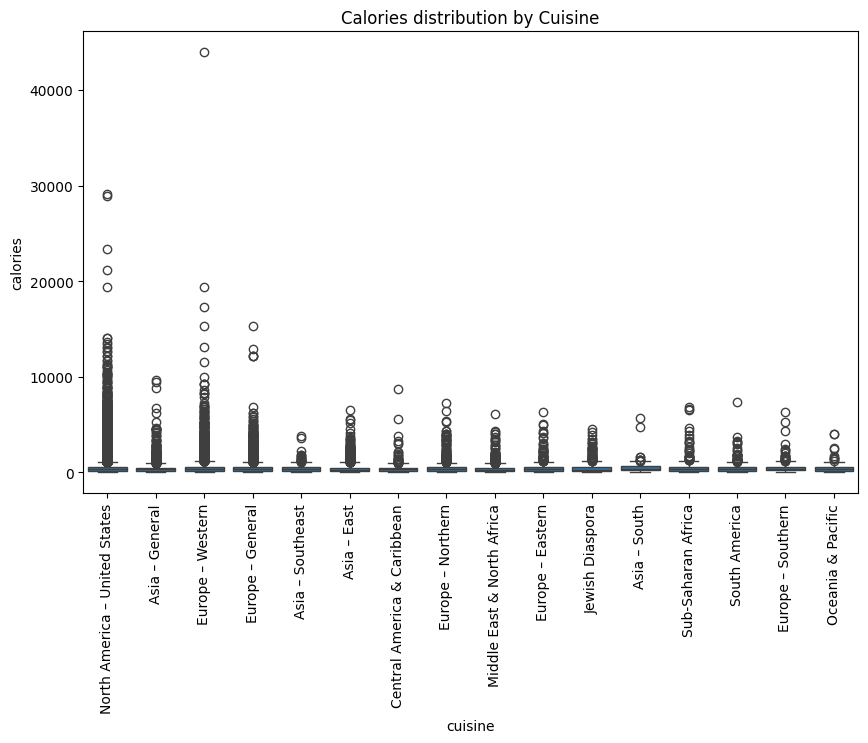

In [14]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
sns.boxplot(data=data, x='cuisine', y='calories')
plt.xticks(rotation=90)
plt.title("Calories distribution by Cuisine")
plt.show()

In [15]:
data[data["calories"] > 2000]

,id,minutes,tags,n_steps,steps,ingredients,n_ingredients,cuisine,cleaned_name,calories,total_fat,sugar,sodium,protein,saturated_fat,carbohydrates
39,40237,40,"[60-minutes-or-less, time-to-make, course, mai...",7,['sift together and make 3 holes in dry ingred...,"['flour', 'sugar', 'cocoa', 'baking soda', 'sa...",9,North America – United States,wacky cake,2252.6,130.0,802.0,101.0,44.0,54.0,117.0
50,124286,35,"[60-minutes-or-less, time-to-make, course, mai...",5,"['mix all cake ingredients till well blended',...","['flour', 'sugar', 'baking soda', 'cocoa powde...",11,North America – United States,chocolate cake,3987.2,369.0,1306.0,260.0,106.0,245.0,205.0
75,83542,25,"[30-minutes-or-less, time-to-make, course, cui...",13,"['preheat oven to 375c', 'beat eggs , add suga...","['eggs', 'brown sugar', 'oil', 'milk', 'molass...",13,North America – United States,muffin,2488.6,199.0,775.0,133.0,87.0,116.0,109.0
100,86768,15,"[15-minutes-or-less, time-to-make, course, mai...",14,"['place a large bowl , filled halfway with ice...","['semisweet chocolate', 'heavy cream', 'butter...",4,North America – United States,chocolate frosting,4076.9,1001.0,1181.0,71.0,53.0,491.0,118.0
117,168590,12,"[15-minutes-or-less, time-to-make, course, cui...",13,"['let cream cheese come to room temperature', ...","['canned chicken', 'green chilies', 'cream che...",6,North America – United States,amigo crisp chicken burrito,2453.4,383.0,17.0,41.0,62.0,211.0,9.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
86230,505267,80,"[time-to-make, course, main-ingredient, cuisin...",14,"['preheat oven to 350 degrees', 'in large glas...","['eggs', 'vegetable oil', 'white sugar', 'real...",14,North America – United States,zucchini spice bundt cake,5808.2,481.0,1647.0,219.0,151.0,204.0,232.0
86245,92900,90,"[time-to-make, course, main-ingredient, cuisin...",8,"['preheat oven to 325', 'butter and flour 2 8""...","['flour', 'cinnamon', 'salt', 'baking soda', '...",13,North America – United States,zucchini walnut spiced bread,3409.3,324.0,1021.0,83.0,65.0,136.0,120.0
86282,192793,10,"[15-minutes-or-less, time-to-make, course, mai...",8,['in a medium sized bowl toss the mixed greens...,"['mixed greens', 'strawberries', 'dried cranbe...",10,North America – United States,zupas chicken salad,2954.6,350.0,806.0,54.0,31.0,91.0,74.0
86287,529308,60,"[60-minutes-or-less, time-to-make, cuisine, pr...",22,"['1', 'peel the onions and cut them in thin ri...","['beef broth', 'butter', 'onions', 'flour', 'o...",10,Europe – Western,zuppa di cipolla al vino rosso,9282.1,142.0,340.0,715.0,746.0,136.0,583.0


In [16]:
# Creating a new column for the saturated fat to calorie ratio
data['sat_fat_to_calories'] = data['saturated_fat'] / data['calories']

# Checking the result
print(data[['cuisine', 'saturated_fat', 'calories', 'sat_fat_to_calories']].head())

                         cuisine  saturated_fat  calories  sat_fat_to_calories
0  North America – United States            0.0      51.5             0.000000
1  North America – United States           18.0     173.4             0.103806
2  North America – United States            0.0     352.9             0.000000
3  North America – United States           10.0     160.2             0.062422
4  North America – United States           24.0     380.7             0.063042


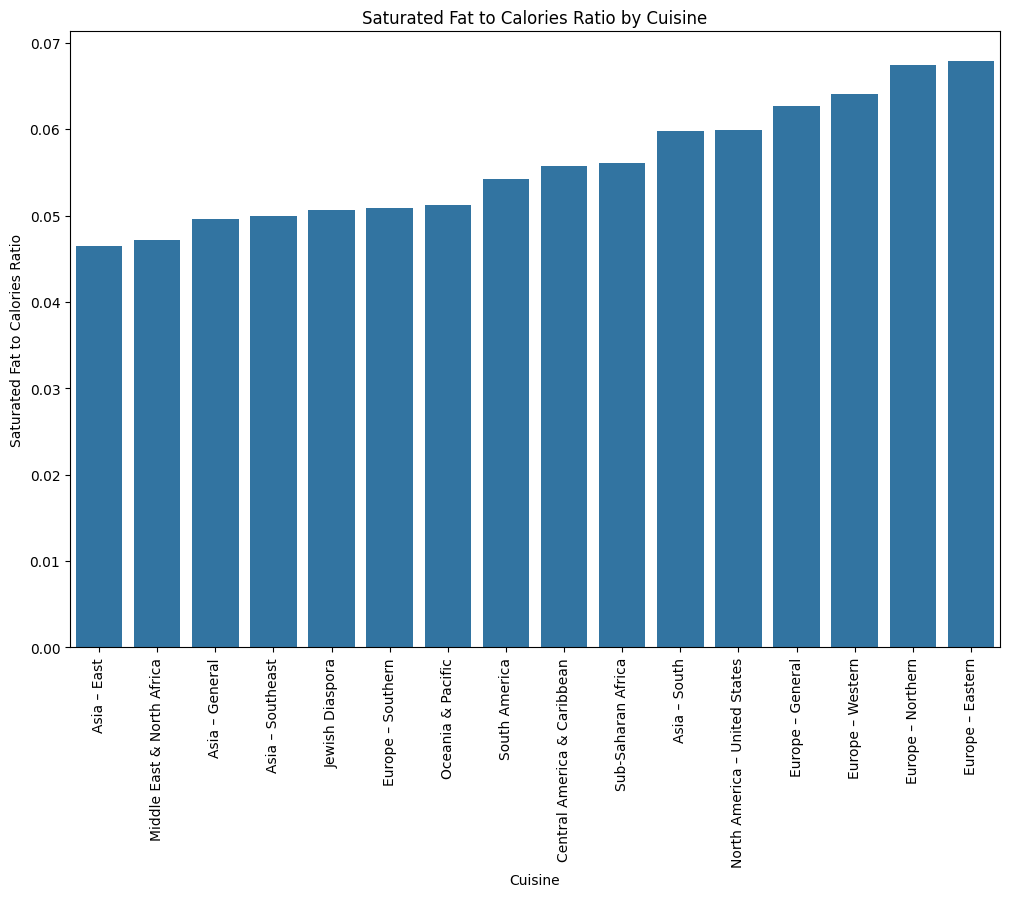

In [17]:
ratio_by_cuisine = data.groupby('cuisine')['sat_fat_to_calories'].mean().sort_values()

# Plot the result
plt.figure(figsize=(12, 8))
sns.barplot(x=ratio_by_cuisine.index, y=ratio_by_cuisine.values)
plt.xticks(rotation=90)
plt.xlabel('Cuisine')
plt.ylabel('Saturated Fat to Calories Ratio')
plt.title('Saturated Fat to Calories Ratio by Cuisine')
plt.show()

/var/folders/pg/1l4d75p90r565jztmcw4v8c00000gn/T/ipykernel_35931/709822848.py:22: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(x='cuisine', y=ratio, data=data, order=order, estimator='mean', ci=None)
/var/folders/pg/1l4d75p90r565jztmcw4v8c00000gn/T/ipykernel_35931/709822848.py:22: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(x='cuisine', y=ratio, data=data, order=order, estimator='mean', ci=None)
/var/folders/pg/1l4d75p90r565jztmcw4v8c00000gn/T/ipykernel_35931/709822848.py:22: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(x='cuisine', y=ratio, data=data, order=order, estimator='mean', ci=None)
/var/folders/pg/1l4d75p90r565jztmcw4v8c00000gn/T/ipykernel_35931/709822848.py:22: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(x='cuisine', y=ratio, dat

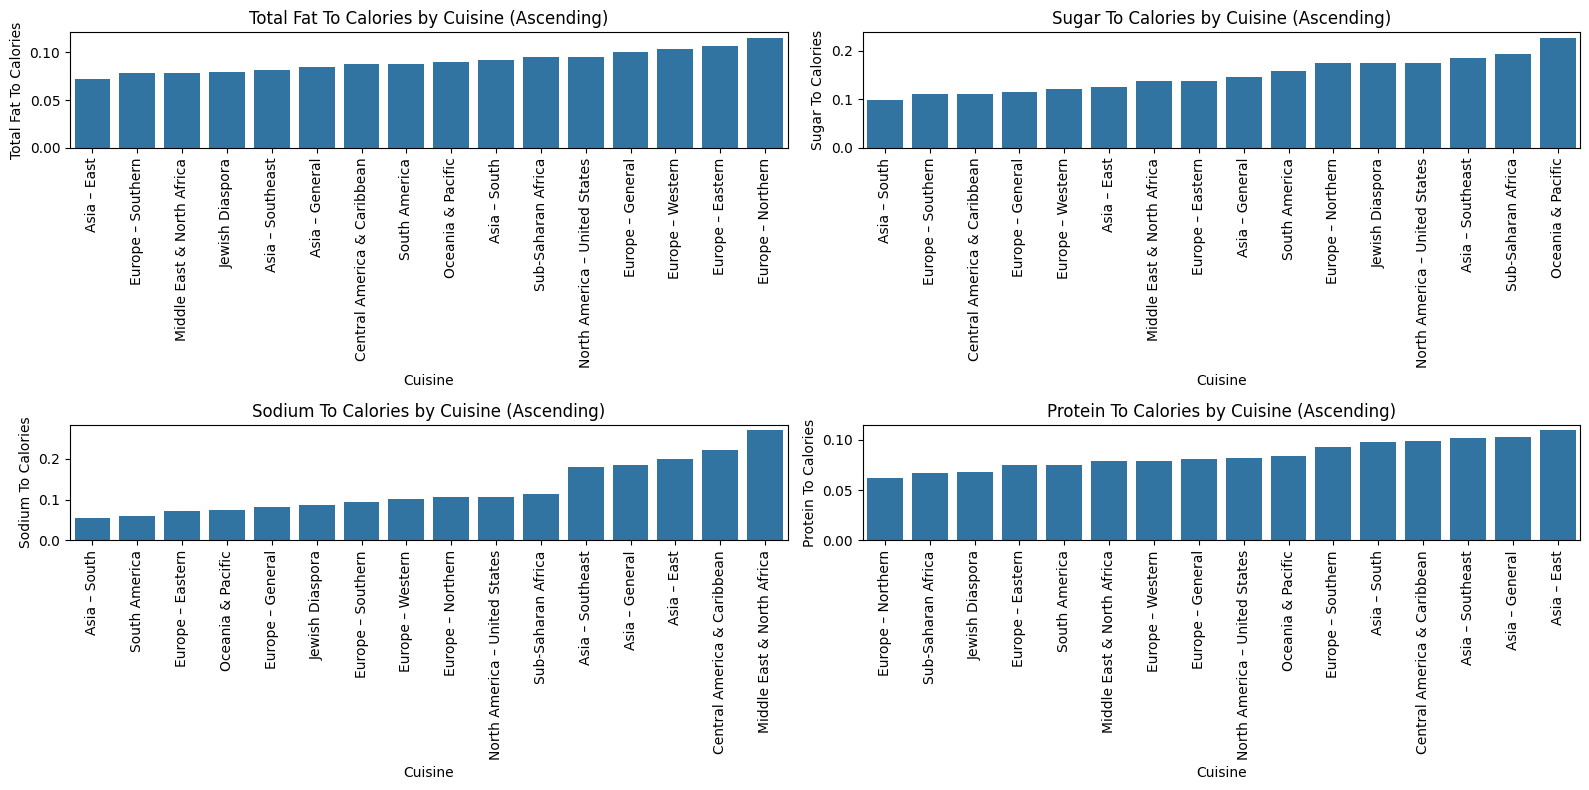

In [28]:
import matplotlib.pyplot as plt
import seaborn as sns

# Create first figure for first 4 ratios
first_part_ratios = [
    'total_fat_to_calories',
    'sugar_to_calories',
    'sodium_to_calories',
    'protein_to_calories'
]

plt.figure(figsize=(16, 8))

for i, ratio in enumerate(first_part_ratios, 1):
    plt.subplot(2, 2, i)

    # Get cuisines ordered by mean ratio
    valid_data = data[np.isfinite(data[ratio])]

    order = valid_data.groupby('cuisine')[ratio].mean().sort_values().index

    sns.barplot(x='cuisine', y=ratio, data=data, order=order, estimator='mean', ci=None)
    plt.xticks(rotation=90)
    plt.xlabel('Cuisine')
    plt.ylabel(f'{ratio.replace("_", " ").title()}')
    plt.title(f'{ratio.replace("_", " ").title()} by Cuisine (Ascending)')

plt.tight_layout()
plt.show()


On remarque que la metric la plus intéressante ici correspond au taux de sodium par calories du plat. 
On remarque les pays du Moyen-Orient/Afrique du Nord ainsi que ceux de des Caraïbes/Amérique central et de l'Asie sont qui salent le plus.

/var/folders/pg/1l4d75p90r565jztmcw4v8c00000gn/T/ipykernel_35931/1278480106.py:16: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(x='cuisine', y=ratio, data=data, order=order, estimator='mean', ci=None)
/var/folders/pg/1l4d75p90r565jztmcw4v8c00000gn/T/ipykernel_35931/1278480106.py:16: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(x='cuisine', y=ratio, data=data, order=order, estimator='mean', ci=None)
/var/folders/pg/1l4d75p90r565jztmcw4v8c00000gn/T/ipykernel_35931/1278480106.py:16: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(x='cuisine', y=ratio, data=data, order=order, estimator='mean', ci=None)


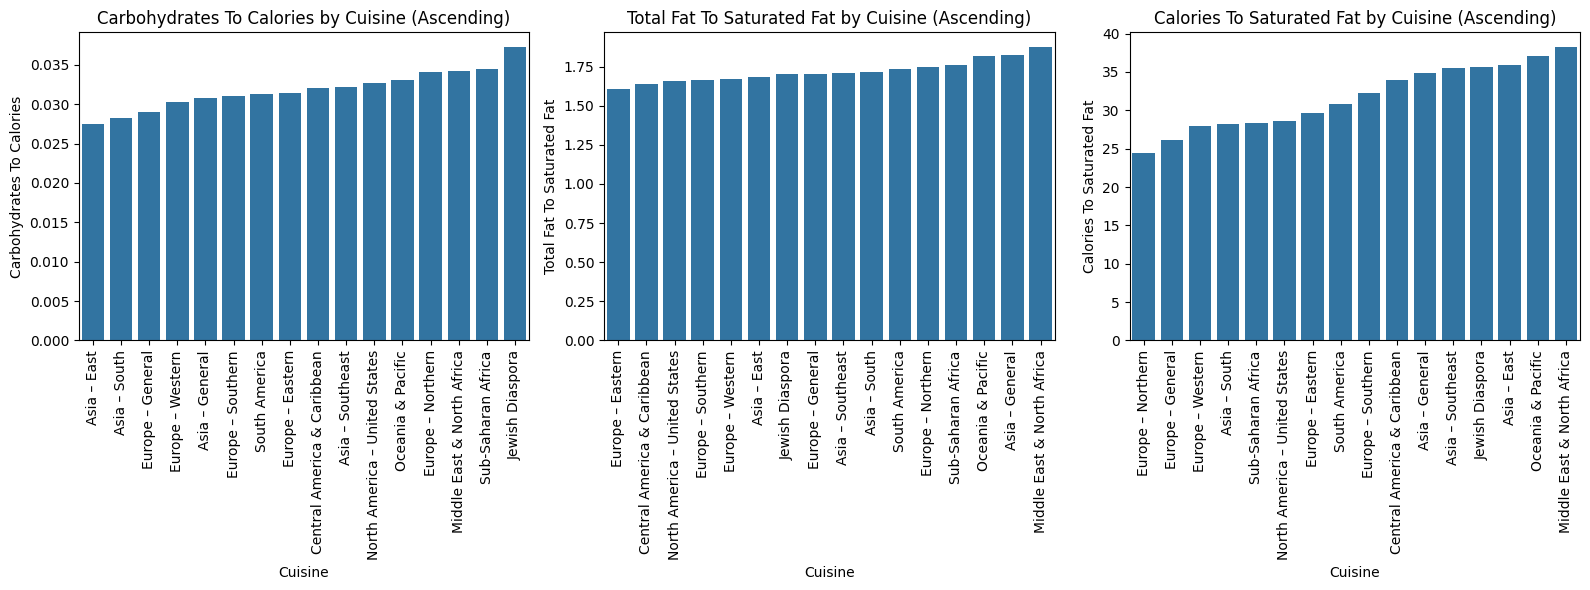

In [29]:
second_part_ratios = [
    'carbohydrates_to_calories',
    'total_fat_to_saturated_fat',
    'calories_to_saturated_fat'
]

plt.figure(figsize=(16, 6))

for i, ratio in enumerate(second_part_ratios, 1):
    plt.subplot(1, 3, i)

    # Get cuisines ordered by mean ratio
    valid_data = data[np.isfinite(data[ratio])]

    order = valid_data.groupby('cuisine')[ratio].mean().sort_values().index
    sns.barplot(x='cuisine', y=ratio, data=data, order=order, estimator='mean', ci=None)
    plt.xticks(rotation=90)
    plt.xlabel('Cuisine')
    plt.ylabel(f'{ratio.replace("_", " ").title()}')
    plt.title(f'{ratio.replace("_", " ").title()} by Cuisine (Ascending)')

plt.tight_layout()
plt.show()

<Figure size 1200x800 with 0 Axes>

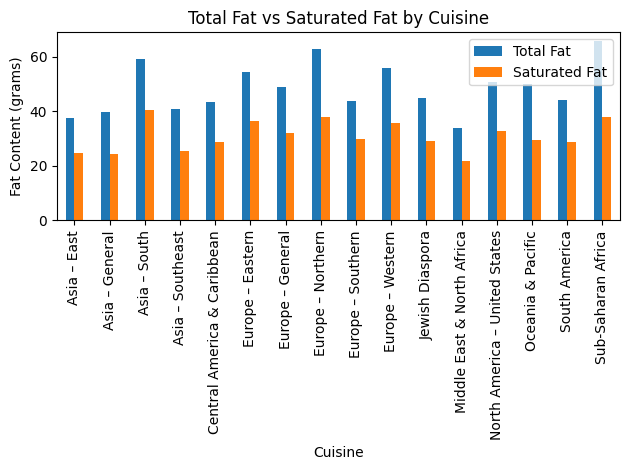

In [30]:
import matplotlib.pyplot as plt

# Group by cuisine and calculate the mean of total fat and saturated fat
total_fat_vs_saturated_fat = data.groupby('cuisine')[['total_fat', 'saturated_fat']].mean()

# Create a bar plot with different colors for total fat and saturated fat
plt.figure(figsize=(12, 8))
total_fat_vs_saturated_fat.plot(kind='bar', color=['#1f77b4', '#ff7f0e'])

# Customize the plot
plt.xticks(rotation=90)
plt.xlabel('Cuisine')
plt.ylabel('Fat Content (grams)')
plt.title('Total Fat vs Saturated Fat by Cuisine')
plt.legend(['Total Fat', 'Saturated Fat'], loc='upper right')

# Show the plot
plt.tight_layout()
plt.show()


,cleaned_name,total_fat,saturated_fat
